In [1]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)
df = pd.DataFrame({
    'study_hours': study_hours,
    'attendance': attendance,
    'previous_mark': previous_mark,
    'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50 # Outlier
df.loc[98, 'attendance'] = -10 # Impossible value

print(df)

df.to_csv('student_data.csv', index=False)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]


# PART A: INSPECT AND CLEAN

1. **Identify and handle the outlier**: The value 50 in study_hours (row 99) is an outlier. Most of the hours in the data set range around 5 with the max being 8, so 50 is clearly an outlier. Since there is only one outlier the simplest thing we can do is to drop it, but if there were a lot of outliers we could cap the values or drop the outliers using a rule like $1.5*IQR$

2. **Feature matrix and target**: The Shape of the Feature matrix is (100,3). It consists of the study_hours, attendance and previous mark columns. All the columns in this dataset are numeric. The target variable is the column final_score.

In [2]:
old_mean = np.mean(df['study_hours'])

dropped_df = df.drop(99)
new_mean = np.mean(dropped_df['study_hours'])

print(f"Old Mean: {old_mean}\t New Mean: {new_mean}")

feature_matrix = df[['study_hours','attendance','previous_mark']]
print("Feature Matrix Shape:",np.shape(feature_matrix))


Old Mean: 5.218916116580629	 New Mean: 4.737399085576119
Feature Matrix Shape: (100, 3)


# PART B: SUMMARIZE

The data contains missing values in study_hours and an impossible attendance value of -10. For this exercise, we fill the missing study hours with the mean of the observed values and replace the impossible attendance value with the mean attendance calculated from the other valid rows. In addition to this upon inspection attendance is filled with decimal values, some of which are above 100 so we can't assume it is percentage or the actual attendance data so we need to clean this column. We do that by clipping the values to be between 1 and 100 and assuming the dataset given is for the percentage of classes attended. The other observation I had in this dataset is that previous_mark is actually greater than 100 for some values but we can assume that the maximum result is greater than 100 and move on. Additionally, study_hours contains some negative values so we have to remove those as well. After that we can calculate the mean, median, and standard deviation for every column.

### Observations 
1. The standard deviation of study_hours is relatively small compared with that of previous_mark, so the study-hour values are less spread out.
2. The mean and median of attendance and final_score are close, suggesting that their distributions are reasonably balanced around their centers.
3. previous_mark has the largest standard deviation among the input features, indicating the greatest spread in its values.

In [3]:
mean = np.nanmean(dropped_df['study_hours'])
dropped_df['study_hours'] = dropped_df['study_hours'].fillna(mean)

mean_attendance = np.mean(dropped_df['attendance'][:98])
dropped_df.loc[98,'attendance'] = mean_attendance 

print(np.min(dropped_df['study_hours']))
print(np.min(dropped_df['attendance']))
print(np.min(dropped_df['previous_mark']))

print()

print(np.max(dropped_df['study_hours']))
print(np.max(dropped_df['attendance']))
print(np.max(dropped_df['previous_mark']))
print()

dropped_df['attendance']=dropped_df['attendance'].clip(lower=0,upper=100)
dropped_df['study_hours']=dropped_df['study_hours'].clip(lower=0)

pd.set_option('display.max_rows', None)

print(dropped_df)

-0.23949020817948874
65.81228784700959
21.38098989896391

8.704556369017876
112.20169166589619
127.79097235982081

    study_hours  attendance  previous_mark  final_score
0      4.737399   70.846293      75.366810    35.178989
1      4.737399   80.793547      78.411768    39.481248
2      4.737399   81.572855      86.245769    48.605167
3      4.737399   76.977227      85.807031    47.329456
4      4.737399   83.387143      49.334959    37.044473
5      4.737399   89.040509      55.932624    40.751177
6      8.158426  100.000000      77.725529    57.171201
7      6.534869   86.745778      77.706789    41.874669
8      4.061051   87.575504      77.725715    46.583807
9      6.085120   84.255541     127.790972    52.866454
10     4.073165   65.812288      78.563358    36.404534
11     4.068540   84.734861      87.033485    50.355310
12     5.483925   85.602302      84.310026    49.411740
13     1.173440  100.000000      79.770869    53.498168
14     1.550164   83.076390      65.270961   

In [4]:
result = dropped_df.agg(['mean','median','std'])
print(result)

        study_hours  attendance  previous_mark  final_score
mean       4.739818   84.926919      70.887878    42.654355
median     4.737399   85.996514      71.228112    42.673003
std        1.777133    8.643795      16.324375     6.106089


# PART C: VISUALIZE 

The scatter plot shows a weak relationship between study hours and final score: the points are widely spread, and there is no clear strong upward or downward pattern. Study hours alone therefore do not explain much of the variation in final scores in this dataset.

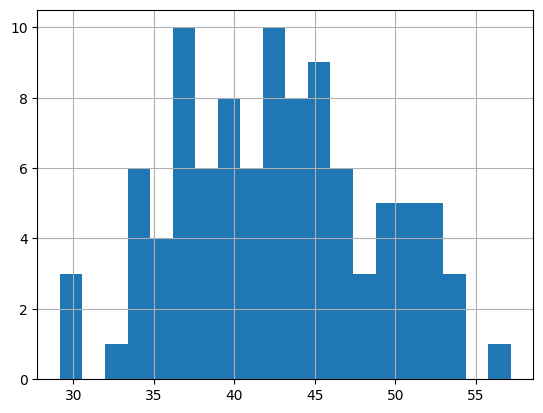

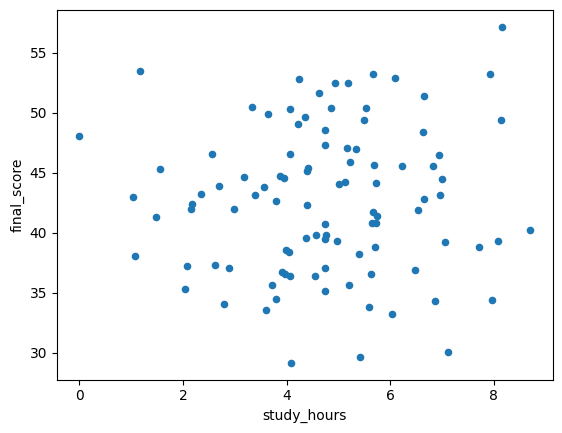

In [5]:
import matplotlib.pyplot as plt

dropped_df['final_score'].hist(bins=20)
dropped_df.plot.scatter(x='study_hours',y='final_score')
plt.show()

# PART D: CORRELATION AND CAUSALITY

The correlation is approximately 0.05, which indicates a very weak positive linear relationship in this cleaned dataset. If a student studies for 10 hours, this correlation does not guarantee a particular score. Correlation describes an overall pattern across observations, not an exact prediction for one person.

Potential lurking or confounding variables include attendance, previous marks, prior knowledge, study quality, and the student's learning environment. These factors could also be related to study time and final scores.

In [6]:
corr = dropped_df['final_score'].corr(dropped_df['study_hours'])
print("Pearson correlation between final score and study hours:",corr)

Pearson correlation between final score and study hours: 0.051500516903046065


# PART E: VECTORS AND DOT PRODUCT

- Weights represent the contribution assigned to each input feature in the weighted sum. A larger weight gives that feature a larger contribution when the feature values are on comparable scales.
- Bias is a constant added to the weighted sum. It allows the result to shift up or down instead of forcing the model's output to depend only on the weighted features.

In [7]:
# PART E: VECTORS AND DOT PRODUCT 

sample_row = dropped_df[['study_hours','attendance','previous_mark']].iloc[0].to_numpy()
weights = [.5,.2,.4]
bias = 5

y = np.dot(sample_row,weights)+bias
print("Predicted:",y)
print("Actual value in the dataset:",dropped_df.loc[0,'final_score'])

Predicted: 51.68468222077693
Actual value in the dataset: 35.17898895329447


# PART F: SCALING

Before scaling, study_hours is centered around roughly 5, while previous_mark is centered around roughly 70 and has a much wider numerical range. A distance-based algorithm such as K-Nearest Neighbors could therefore be influenced more by previous_mark simply because its values have a larger scale. Standardization puts both features on a comparable scale, so neither dominates distance calculations solely because of its units.

In [8]:
cols_scaled = ['study_hours','previous_mark']
dropped_df[cols_scaled] = (dropped_df[cols_scaled] - np.mean(dropped_df[cols_scaled], axis=0))/np.std(dropped_df[cols_scaled],axis=0,ddof=0)

print(np.mean(dropped_df[cols_scaled],axis=0))
print(np.std(dropped_df[cols_scaled],axis=0))

study_hours     -1.735424e-16
previous_mark    1.155081e-15
dtype: float64
study_hours      1.0
previous_mark    1.0
dtype: float64
